DATA VALIDATION
----------------
AATTGGCC : Valid sequence
AATTTGCC : Valid sequence
ATGCATGC : Valid sequence
ATGXGGCC : Invalid sequence
 : Empty sequence

NUMERICAL FEATURES
------------------
AATTGGCC : [2, 2, 2, 2]
AATTTGCC : [2, 3, 1, 2]
ATGCATGC : [2, 2, 2, 2]

DISTANCE COMPARISON
-------------------

Sequence 1: AATTGGCC
Sequence 2: AATTTGCC
Euclidean Distance: 1.4142135623730951
Manhattan Distance: 2

Sequence 1: AATTGGCC
Sequence 2: ATGCATGC
Euclidean Distance: 0.0
Manhattan Distance: 0

Sequence 1: AATTTGCC
Sequence 2: ATGCATGC
Euclidean Distance: 1.4142135623730951
Manhattan Distance: 2

EUCLIDEAN DISTANCE MATRIX
-------------------------
[0.0, 1.41, 0.0]
[1.41, 0.0, 1.41]
[0.0, 1.41, 0.0]

MANHATTAN DISTANCE MATRIX
-------------------------
[0, 2, 0]
[2, 0, 2]
[0, 2, 0]

FINAL SUMMARY
-------------
Total sequences: 5
Valid sequences: 3
Invalid sequences: 2
Preprocessing completed.
Distance calculations completed.
Please upload your DNA sequence file.


Saving genes (1).fasta to genes (1) (1).fasta

FILE INFORMATION
----------------
Uploaded file: genes (1) (1).fasta
File extension: .fasta

SEQUENCE FILE SUMMARY
---------------------
Total sequences read: 5
Valid DNA sequences: 5
Invalid or empty sequences: 0

FIRST FIVE SEQUENCES
--------------------

Gene: hsa:10458
Sequence: ATGTCTCTGTCTCGCTCAGAGGAGATGCACCGGCTCACGGAAAATGTCTATAAGACCATCATGGAGCAGTTCAACCCTAGCCTCCGGAACTTCATCGCCA

Gene: hsa:3643
Sequence: ATGGCCACCGGGGGCCGGCGGGGGGCGGCGGCCGCGCCGCTGCTGGTGGCGGTGGCCGCGCTGCTACTGGGCGCCGCGGGCCACCTGTACCCCGGAGAGG

Gene: hsa:672
Sequence: ATGGATTTATCTGCTCTTCGCGTTGAAGAAGTACAAAATGTCATTAATGCTATGCAGAAAATCTTAGAGTGTCCCATCTGTCTGGAGTTGATCAAGGAAC

Gene: hsa:7157
Sequence: ATGGAGGAGCCGCAGTCAGATCCTAGCGTCGAGCCCCCTCTGAGTCAGGAAACATTTTCAGACCTATGGAAACTACTTCCTGAAAACAACGTTCTGTCCC

Gene: hsa:5742
Sequence: ATGAGCCGGAGTCTCTTGCTCTGGTTCTTGCTGTTCCTGCTCCTGCTCCCGCCGCTCCCCGTCCTGCTCGCGGACCCAGGGGCGCCCACGCCAGTGAATC

Total sequences used for clustering: 5

FEATURE EXTRACTION
-

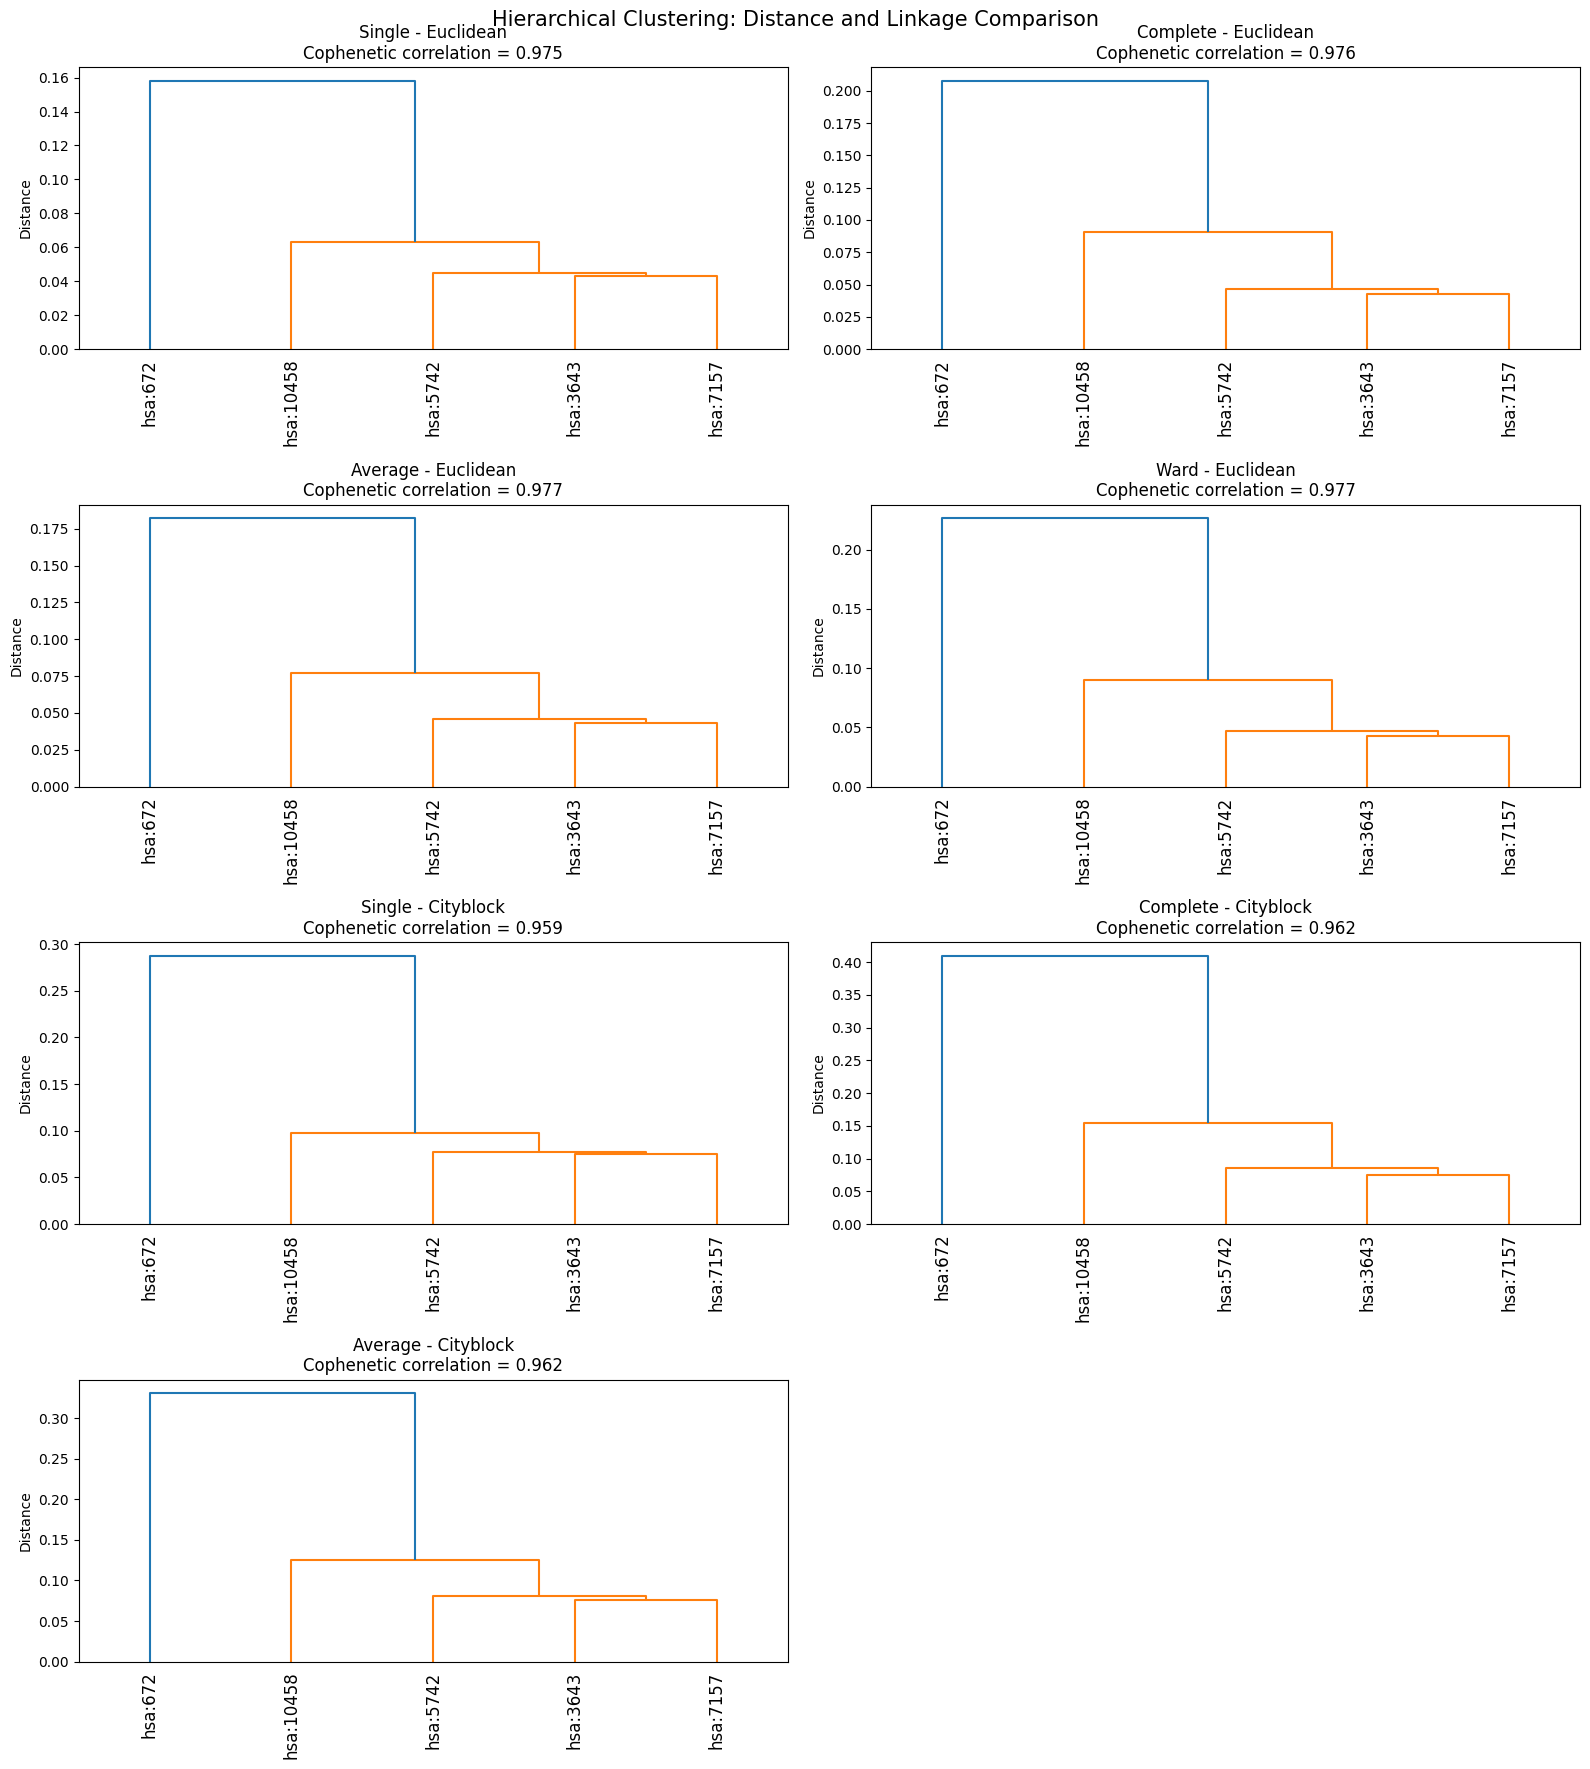


DISTANCE AND LINKAGE COMPARISON
--------------------------------
 Distance  Linkage  Cophenetic Score
euclidean  average          0.977065
euclidean     ward          0.977004
euclidean complete          0.976027
euclidean   single          0.975267
cityblock  average          0.962157
cityblock complete          0.961531
cityblock   single          0.959402


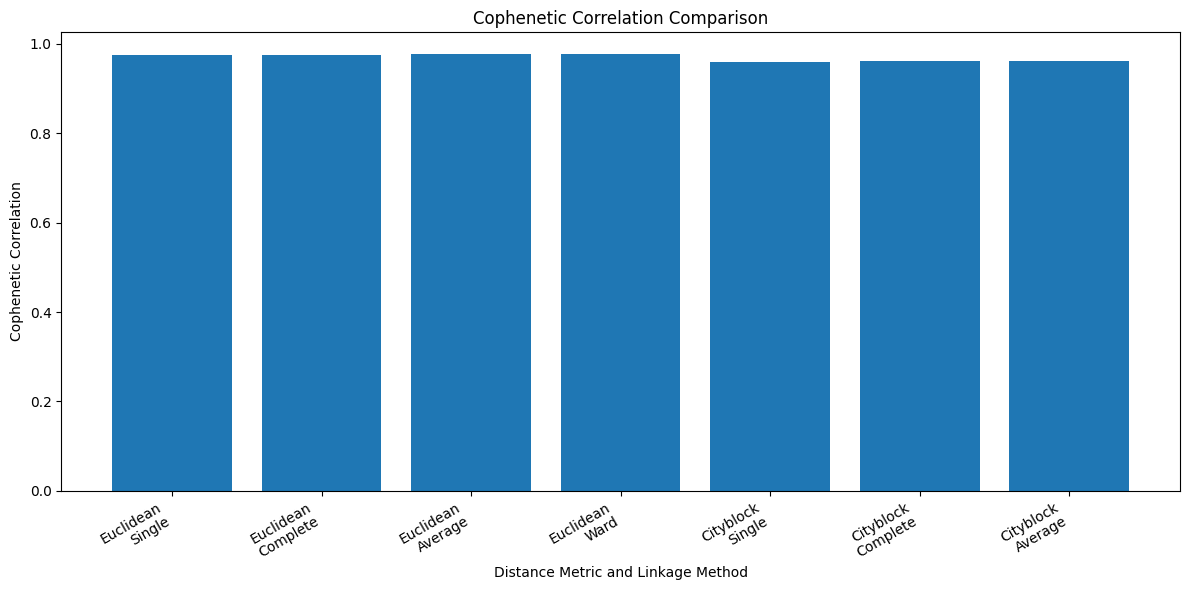


BEST CLUSTERING COMBINATION
---------------------------
Distance metric: euclidean
Linkage method: average
Cophenetic score: 0.9771

FINAL CLUSTERS
--------------
     Gene  Length  GC_content  Cluster
hsa:10458    1659    0.617239        2
 hsa:3643    4149    0.556038        1
  hsa:672    5592    0.412196        3
 hsa:7157    1182    0.568528        1
 hsa:5742    1800    0.569444        1

CLUSTER SUMMARY
----------------
         Length  GC_content  Number of Genes
Cluster                                     
1        2377.0       0.565                3
2        1659.0       0.617                1
3        5592.0       0.412                1


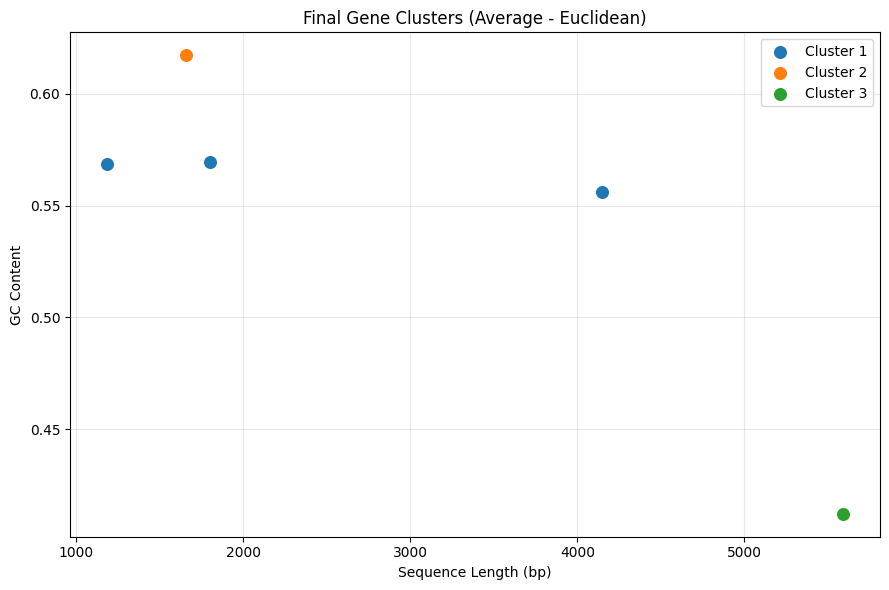

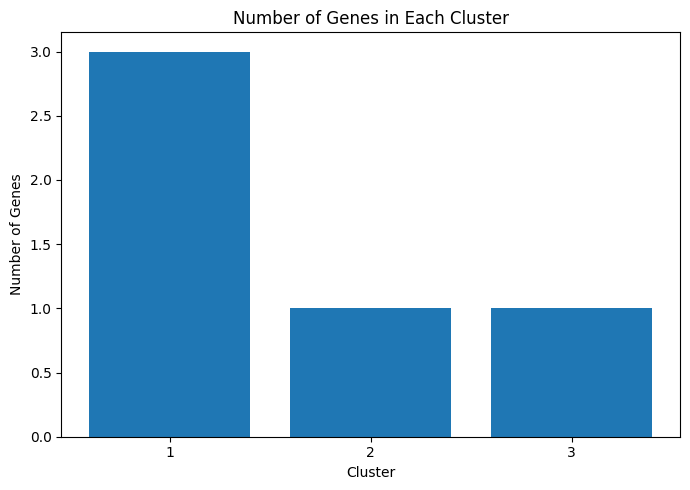


FINAL SUMMARY
-------------
Input file: genes (1) (1).fasta
Total valid sequences: 5
Distance metrics compared: Euclidean and Manhattan
Linkage methods compared: Single, Complete, Average, Ward
Best distance metric: euclidean
Best linkage method: average
Best cophenetic score: 0.9771
Number of clusters: 3
Clustering completed successfully.


In [3]:
!pip install -q biopython anthropic

import math

# =====================================
# 1. PREPROCESSING - CLEAN DNA SEQUENCES
# =====================================

def clean_sequence(seq):

    seq = seq.strip().upper()

    if seq == "":
        return "Empty sequence"

    for base in seq:
        if base not in "ATGC":
            return "Invalid sequence"

    return "Valid sequence"


# =====================================
# 2. FLAG INVALID DATA
# =====================================

sequences = [
    "AATTGGCC",
    "AATTTGCC",
    "ATGCATGC",
    "ATGXGGCC",
    ""
]

valid_sequences = []

print("DATA VALIDATION")
print("----------------")

for seq in sequences:

    result = clean_sequence(seq)

    print(seq, ":", result)

    if result == "Valid sequence":
        valid_sequences.append(seq)


# =====================================
# 3. CONVERT DNA INTO NUMBERS
# =====================================

def base_counts(seq):

    counts = []

    counts.append(seq.count("A"))
    counts.append(seq.count("T"))
    counts.append(seq.count("G"))
    counts.append(seq.count("C"))

    return counts


print("\nNUMERICAL FEATURES")
print("------------------")

for seq in valid_sequences:

    print(seq, ":", base_counts(seq))


# =====================================
# 4. EUCLIDEAN DISTANCE
# =====================================

def euclidean(a, b):

    total = 0

    for i in range(len(a)):

        total += (a[i] - b[i]) ** 2

    return math.sqrt(total)


# =====================================
# 5. MANHATTAN DISTANCE
# =====================================

def manhattan(a, b):

    total = 0

    for i in range(len(a)):

        total += abs(a[i] - b[i])

    return total


# =====================================
# 6. COMPARE DISTANCES
# =====================================

print("\nDISTANCE COMPARISON")
print("-------------------")

for i in range(len(valid_sequences)):

    for j in range(i + 1, len(valid_sequences)):

        a = base_counts(valid_sequences[i])
        b = base_counts(valid_sequences[j])

        print("\nSequence 1:", valid_sequences[i])
        print("Sequence 2:", valid_sequences[j])

        print("Euclidean Distance:", euclidean(a, b))

        print("Manhattan Distance:", manhattan(a, b))


# =====================================
# 7. DISTANCE MATRIX
# =====================================

print("\nEUCLIDEAN DISTANCE MATRIX")
print("-------------------------")

for i in range(len(valid_sequences)):

    row = []

    for j in range(len(valid_sequences)):

        a = base_counts(valid_sequences[i])
        b = base_counts(valid_sequences[j])

        row.append(round(euclidean(a, b), 2))

    print(row)


print("\nMANHATTAN DISTANCE MATRIX")
print("-------------------------")

for i in range(len(valid_sequences)):

    row = []

    for j in range(len(valid_sequences)):

        a = base_counts(valid_sequences[i])
        b = base_counts(valid_sequences[j])

        row.append(manhattan(a, b))

    print(row)


# =====================================
# 8. FINAL SUMMARY
# =====================================

print("\nFINAL SUMMARY")
print("-------------")

print("Total sequences:", len(sequences))

print("Valid sequences:", len(valid_sequences))

print("Invalid sequences:", len(sequences) - len(valid_sequences))

print("Preprocessing completed.")

print("Distance calculations completed.")

#============================================================
#Hierarchical Clustering & Linkage Method Comparison
# DNA SEQUENCE ANALYSIS
# ============================================================

# ============================================================
# 1. INSTALL AND IMPORT LIBRARIES
# ============================================================

%pip install -q biopython scipy pandas numpy matplotlib

import os
import io
import csv
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from google.colab import files
from Bio import SeqIO

from scipy.spatial.distance import pdist
from scipy.cluster.hierarchy import (
    linkage,
    dendrogram,
    fcluster,
    cophenet
)


# ============================================================
# 2. UPLOAD DNA SEQUENCE FILE
# ============================================================

print("Please upload your DNA sequence file.")

uploaded = files.upload()

if not uploaded:
    raise ValueError("No file was uploaded.")

filename = next(iter(uploaded))
file_content = uploaded[filename]

extension = os.path.splitext(filename)[1].lower()

print("\nFILE INFORMATION")
print("----------------")
print("Uploaded file:", filename)
print("File extension:", extension)


# ============================================================
# 3. IDENTIFY FILE FORMAT
# ============================================================

format_map = {
    ".fasta": "fasta",
    ".fa": "fasta",
    ".fna": "fasta",
    ".ffn": "fasta",
    ".fas": "fasta",
    ".gb": "genbank",
    ".gbk": "genbank",
    ".gbff": "genbank",
    ".genbank": "genbank",
    ".fastq": "fastq",
    ".fq": "fastq",
    ".embl": "embl"
}

names = []
sequences = []

file_text = file_content.decode("utf-8-sig")


# ============================================================
# 4. READ DNA SEQUENCES
# ============================================================

# Read FASTA, GenBank, FASTQ and EMBL files

if extension in format_map:

    file_format = format_map[extension]

    records = SeqIO.parse(
        io.StringIO(file_text),
        file_format
    )

    for record in records:

        names.append(record.id)
        sequences.append(str(record.seq).upper())


# Read CSV and TSV files

elif extension in [".csv", ".tsv"]:

    delimiter = "," if extension == ".csv" else "\t"

    reader = csv.DictReader(
        io.StringIO(file_text),
        delimiter=delimiter
    )

    if not reader.fieldnames:
        raise ValueError("The CSV/TSV file has no column headers.")

    # Identify column names
    column_map = {
        column.strip().lower(): column
        for column in reader.fieldnames
    }

    # Find gene name column
    gene_column = next(
        (
            column_map[column]
            for column in ["gene", "gene_id", "name", "id"]
            if column in column_map
        ),
        None
    )

    # Find DNA sequence column
    sequence_column = next(
        (
            column_map[column]
            for column in ["sequence", "dna_sequence", "seq"]
            if column in column_map
        ),
        None
    )

    if sequence_column is None:
        raise ValueError(
            "Could not find a DNA sequence column."
        )

    for index, row in enumerate(reader, start=1):

        gene_name = (
            row.get(gene_column)
            if gene_column else f"Sequence_{index}"
        )

        sequence = row.get(sequence_column)

        if sequence:

            names.append(
                gene_name.strip() if gene_name else f"Sequence_{index}"
            )

            sequences.append(sequence.upper())


else:

    raise ValueError(
        "Unsupported file format: " + extension
    )


# ============================================================
# 5. CLEAN AND VALIDATE DNA SEQUENCES
# ============================================================

original_count = len(sequences)

cleaned_names = []
cleaned_sequences = []

for name, sequence in zip(names, sequences):

    # Remove spaces and line breaks
    sequence = re.sub(r"\s+", "", sequence.upper())

    # Accept only A, T, G and C
    if sequence and set(sequence).issubset(set("ATGC")):

        cleaned_names.append(name)
        cleaned_sequences.append(sequence)


names = cleaned_names
sequences = cleaned_sequences

invalid_count = original_count - len(sequences)

print("\nSEQUENCE FILE SUMMARY")
print("---------------------")
print("Total sequences read:", original_count)
print("Valid DNA sequences:", len(sequences))
print("Invalid or empty sequences:", invalid_count)

print("\nFIRST FIVE SEQUENCES")
print("--------------------")

for name, sequence in list(zip(names, sequences))[:5]:

    print("\nGene:", name)
    print("Sequence:", sequence[:100])


# Check the minimum number of sequences

if len(sequences) < 3:

    raise ValueError(
        "At least 3 valid DNA sequences are required "
        "for this clustering analysis."
    )


# ============================================================
# 6. LIMIT NUMBER OF SEQUENCES
# ============================================================

MAX_SEQUENCES = 500

if len(sequences) > MAX_SEQUENCES:

    selected = np.random.default_rng(42).choice(
        len(sequences),
        MAX_SEQUENCES,
        replace=False
    )

    names = [names[i] for i in selected]
    sequences = [sequences[i] for i in selected]

    print(
        "\nMore than 500 sequences were uploaded."
    )

    print(
        "A random sample of 500 sequences will be analysed."
    )


print("\nTotal sequences used for clustering:", len(sequences))


# ============================================================
# 7. CONVERT DNA SEQUENCES INTO NUMERICAL FEATURES
# ============================================================

def base_frequencies(seq):

    total = len(seq)

    return [
        seq.count("A") / total,
        seq.count("T") / total,
        seq.count("G") / total,
        seq.count("C") / total
    ]


# Calculate A, T, G and C frequencies for each sequence

features = np.array([
    base_frequencies(seq)
    for seq in sequences
])

print("\nFEATURE EXTRACTION")
print("------------------")
print("Features used: A, T, G and C frequencies")
print("Feature matrix shape:", features.shape)


# ============================================================
# 8. CALCULATE DISTANCE MATRICES
# ============================================================

distance_metrics = [
    "euclidean",
    "cityblock"
]

distance_matrices = {}

for metric in distance_metrics:

    distance_matrices[metric] = pdist(
        features,
        metric=metric
    )

print("\nDISTANCE CALCULATIONS COMPLETED")
print("--------------------------------")
print("Distance metrics: Euclidean and Manhattan")


# ============================================================
# 9. COMPARE LINKAGE METHODS
# ============================================================

methods = [
    "single",
    "complete",
    "average",
    "ward"
]

results = {}
scores = {}

for metric in distance_metrics:

    for method in methods:

        # Ward linkage is only valid with Euclidean distance
        if method == "ward" and metric != "euclidean":
            continue

        distances = distance_matrices[metric]

        # Perform hierarchical clustering
        Z = linkage(
            distances,
            method=method
        )

        # Calculate cophenetic correlation
        score, _ = cophenet(
            Z,
            distances
        )

        key = (metric, method)

        results[key] = Z
        scores[key] = score

        if np.isfinite(score):

            print(
                metric.capitalize(),
                "+",
                method.capitalize(),
                "=",
                round(score, 4)
            )

        else:

            print(
                metric.capitalize(),
                "+",
                method.capitalize(),
                "= Undefined"
            )


# ============================================================
# 10. VISUALIZE ALL DENDROGRAMS
# ============================================================

fig, axes = plt.subplots(
    4,
    2,
    figsize=(16, 18)
)

axes = axes.flatten()

show_labels = len(names) <= 40

for ax, (key, Z) in zip(axes, results.items()):

    metric, method = key

    if show_labels:

        dendrogram(
            Z,
            labels=names,
            ax=ax,
            leaf_rotation=90
        )

    else:

        dendrogram(
            Z,
            no_labels=True,
            ax=ax
        )

    if np.isfinite(scores[key]):
        score_text = f"{scores[key]:.3f}"
    else:
        score_text = "Undefined"

    ax.set_title(
        f"{method.capitalize()} - {metric.capitalize()}\n"
        f"Cophenetic correlation = {score_text}"
    )

    ax.set_ylabel("Distance")


# Hide unused subplots

for i in range(len(results), len(axes)):

    axes[i].set_visible(False)


plt.suptitle(
    "Hierarchical Clustering: Distance and Linkage Comparison",
    fontsize=15
)

plt.tight_layout()
plt.show()


# ============================================================
# 11. COMPARE COPHENETIC CORRELATION SCORES
# ============================================================

# Keep only valid cophenetic scores

valid_scores = {
    key: score
    for key, score in scores.items()
    if np.isfinite(score)
}

if not valid_scores:

    raise ValueError(
        "No valid cophenetic correlation scores were obtained."
    )


# Create comparison dataframe

score_df = pd.DataFrame([

    {
        "Distance": metric,
        "Linkage": method,
        "Cophenetic Score": score
    }

    for (metric, method), score in valid_scores.items()

])


score_df = score_df.sort_values(
    "Cophenetic Score",
    ascending=False
)


print("\nDISTANCE AND LINKAGE COMPARISON")
print("--------------------------------")

print(
    score_df.to_string(index=False)
)


# Visualize cophenetic correlation scores

plt.figure(figsize=(12, 6))

labels = [

    metric.capitalize() + "\n" + method.capitalize()

    for metric, method in valid_scores

]

values = list(valid_scores.values())

plt.bar(
    labels,
    values
)

plt.title("Cophenetic Correlation Comparison")
plt.xlabel("Distance Metric and Linkage Method")
plt.ylabel("Cophenetic Correlation")

plt.xticks(
    rotation=30,
    ha="right"
)

plt.tight_layout()
plt.show()


# ============================================================
# 12. SELECT BEST METHOD AND CREATE CLUSTERS
# ============================================================

# Select the method with the highest valid cophenetic score

best = max(
    valid_scores,
    key=valid_scores.get
)

best_metric, best_method = best


print("\nBEST CLUSTERING COMBINATION")
print("---------------------------")

print("Distance metric:", best_metric)
print("Linkage method:", best_method)

print(
    "Cophenetic score:",
    round(valid_scores[best], 4)
)


# Create a maximum of 3 clusters

number_of_clusters = min(
    3,
    len(sequences)
)

clusters = fcluster(
    results[best],
    t=number_of_clusters,
    criterion="maxclust"
)


# ============================================================
# 13. CREATE FINAL CLUSTER DATAFRAME
# ============================================================

df = pd.DataFrame({

    "Gene": names,

    "Length": [
        len(seq)
        for seq in sequences
    ],

    "GC_content": [

        (seq.count("G") + seq.count("C")) / len(seq)

        for seq in sequences

    ],

    "Cluster": clusters

})


print("\nFINAL CLUSTERS")
print("--------------")

print(
    df.to_string(index=False)
)


# ============================================================
# 14. CLUSTER SUMMARY
# ============================================================

print("\nCLUSTER SUMMARY")
print("----------------")

cluster_summary = (

    df.groupby("Cluster")

    .agg({

        "Length": "mean",
        "GC_content": "mean",
        "Gene": "count"

    })

    .rename(
        columns={"Gene": "Number of Genes"}
    )

    .round(3)

)

print(cluster_summary)


# ============================================================
# 15. VISUALIZE FINAL CLUSTERS
# ============================================================

plt.figure(figsize=(9, 6))

for cluster in sorted(df["Cluster"].unique()):

    group = df[df["Cluster"] == cluster]

    plt.scatter(

        group["Length"],
        group["GC_content"],

        label=f"Cluster {cluster}",

        s=70

    )


plt.xlabel("Sequence Length (bp)")
plt.ylabel("GC Content")

plt.title(

    f"Final Gene Clusters "
    f"({best_method.capitalize()} - "
    f"{best_metric.capitalize()})"

)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# ============================================================
# 16. CLUSTER SIZE VISUALIZATION
# ============================================================

cluster_counts = (

    df["Cluster"]

    .value_counts()

    .sort_index()

)


plt.figure(figsize=(7, 5))

plt.bar(

    cluster_counts.index.astype(str),
    cluster_counts.values

)

plt.xlabel("Cluster")
plt.ylabel("Number of Genes")

plt.title("Number of Genes in Each Cluster")

plt.tight_layout()
plt.show()


# ============================================================
# 17. FINAL SUMMARY
# ============================================================

print("\nFINAL SUMMARY")
print("-------------")

print("Input file:", filename)

print("Total valid sequences:", len(sequences))

print("Distance metrics compared: Euclidean and Manhattan")

print("Linkage methods compared: Single, Complete, Average, Ward")

print("Best distance metric:", best_metric)

print("Best linkage method:", best_method)

print(
    "Best cophenetic score:",
    round(valid_scores[best], 4)
)

print(
    "Number of clusters:",
    len(np.unique(clusters))
)

print("Clustering completed successfully.")

